# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [3]:
import os
import rioxarray as rioxr
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [5]:
# Import NIR TIF file
fp = os.path.join('..','data','rioxarray_lesson_data', 'NAIP_SB_nir.tif')
nir = rioxr.open_rasterio(fp)
nir

<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [6]:
# Access attributes directly 
print('Shape:', nir.shape)
print('Data type:', nir.dtype)

Shape: (1, 3208, 2419)
Data type: uint8


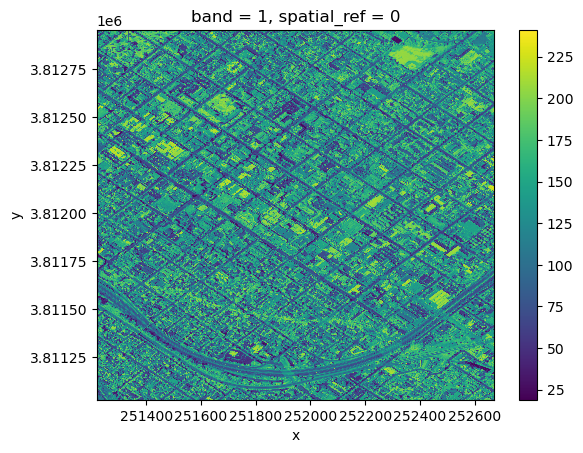

In [9]:
nir.plot()

## Drop a dimension

The raster has an unnecessary extra dimension: band. 

In [11]:
print('Sizes of dimnesions:', dict(nir.sizes))

Sizes of dimnesions: {'band': 1, 'y': 3208, 'x': 2419}


- `band` has length 1, so it makes the `xarray` 3-dimensional for no reason
- `squeeze` removes a dimension of length 1
- `drop = True` removes the coordinates for that dimension

In [14]:
# Original dimensions and coordinates
print(nir.dims, nir.coords, '\n')

# Remove length 1 dimension (band) and its coordinate
nir = nir.squeeze('band')
print(nir.dims, nir.coords, '\n')

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

('y', 'x') Coordinates:
    band         int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 



We are not losing any information because we already know where we are at. 

## `rio` accessor

In [17]:
# Examine this raster attributes using rio accessor
print('Number of bands:', nir.rio.count)
print('Height:', nir.rio.height)
print('Width:', nir.rio.width, '\n')

print('CRS:', nir.rio.crs, '\n')

print('Spatial bounding box:')
print(nir.rio.bounds())

Number of bands: 1
Height: 3208
Width: 2419 

CRS: EPSG:26911 

Spatial bounding box:
(251218.8, 3811027.2, 252670.19999999998, 3812952.0)


In [18]:
## Multi-band raster

In [19]:
# Import RGB TIF file
fp = os.path.join('..','data','rioxarray_lesson_data', 'NAIP_SB_rgb.tif')
rgb = rioxr.open_rasterio(fp)
rgb

<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Check in:
Obtain this information: shape, number of bands, data type, crs

In [25]:
print('Shape:', rgb.shape) # does not come from geospatial information (do not use rio)
print('Data type:', rgb.dtype) 
print('Number of bands:', rgb.rio.count) # comes from the geospatial information (use rio)
print('CRS:', rgb.rio.crs)

Shape: (3, 3208, 2419)
Data type: uint8
Number of bands: 3
CRS: EPSG:26911


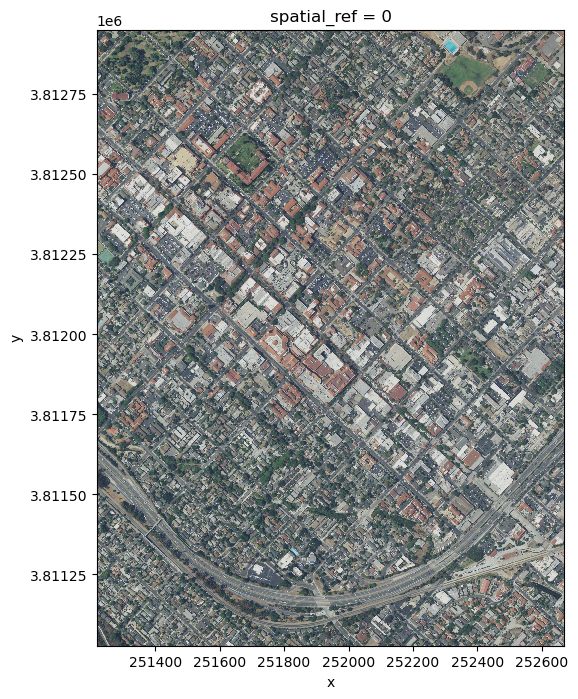

In [27]:
# Plot the three bands as RGB image
rgb_aspect_ratio = rgb.rio.width / rgb.rio.height # Raster's aspect ratio
rgb.plot.imshow(figsize=(8*rgb_aspect_ratio, 8)) # `imshow()` plots the `rgb` raster by combining the 3 bands to create an image

ratio = width/height

dimensions = (1,1)

same ratios = (width/height, 1)

## Clip raster

Our AOI is a few blocks around the NCEAS building, outlined in a GeoJSON file

<Axes: >

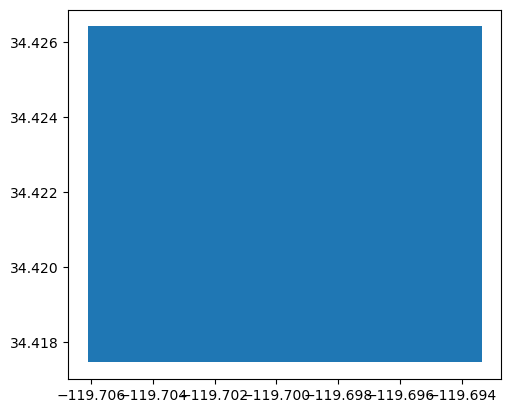

In [28]:
fp = os.path.join('..','data','rioxarray_lesson_data', 'SB_aoi.geojson')
aoi = gpd.read_file(fp)
aoi.plot()

In [29]:
# Examine the CRSs
print('aoi CRS:', aoi.crs) # don't use `rio` because it is a GeoDataFrame and not an xarray
print('nir CRS:', nir.rio.crs)
print('rgb CRS:', rgb.rio.crs)

aoi CRS: EPSG:4326
nir CRS: EPSG:26911
rgb CRS: EPSG:26911


In [30]:
# Reproject AOI to the RGB CRS
aoi = aoi.to_crs(rgb.rio.crs)
assert aoi.crs == rgb.rio.crs

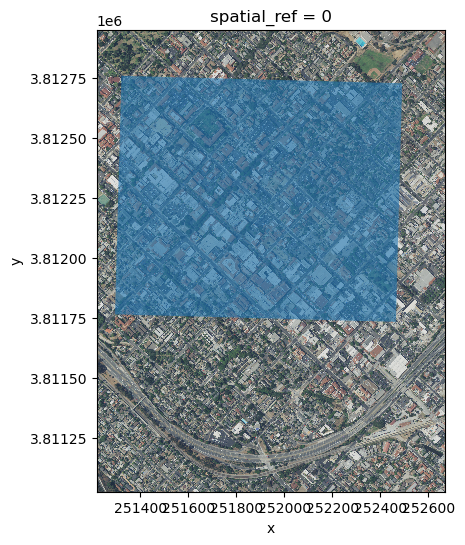

In [31]:
# Plot RGB raster with the AOI overlay
fig, ax = plt.subplots(figsize = (6*rgb_aspect_ratio, 6))
rgb.plot.imshow(ax = ax)
aoi.plot(ax = ax, alpha = 0.6)
plt.show()

In [32]:
aoi.total_bounds

array([ 251294.31339082, 3811734.95697039,  252490.65041356,
       3812760.09703315])

In [36]:
rgb_clipped = rgb.rio.clip_box(*aoi.total_bounds)

In [37]:
nir_clipped = nir.rio.clip_box(*aoi.total_bounds)

Original shape: (3208, 2419)
Clipped shape: (1710, 1995)


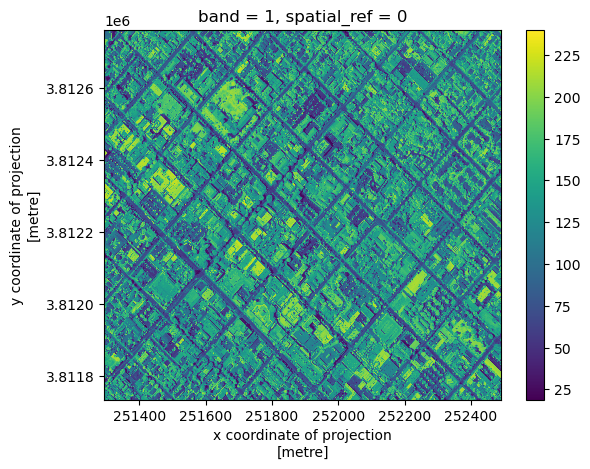

In [38]:
# Examine clipped data
print('Original shape:', nir.shape)
print('Clipped shape:', nir_clipped.shape)
nir_clipped.plot()

## Raster math 

We will compute the **Normalized Difference Vegetation Index (NDVI)** over our AOI.

NDVI checks whether an area have live green vegetation.

NDVI is always between -1 and 1: values about 0.6 correspond to lush vegetation; water roofs pavement, close to zero or negative; sand, rock, snow, 0.1 and below. Generally above ~0.1 is vegetation.

NDVI uses the NIR and red bands:

$$ NDVI = \frac{NIR - Red}{NIR + Red}$$

In [39]:
# Select dimension by name and coordinate by lavel 
red_clipped = rgb_clipped.sel(band = 1)
red_clipped

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [40]:
ndvi = (nir_clipped - red_clipped)/(nir_clipped + red_clipped)
ndvi

<xarray.DataArray (y: 1710, x: 1995)> Size: 27MB
array([[           inf, 3.37500000e+00, 9.25000000e+00, ...,
        5.85000000e+01, 1.18811881e+00, 2.46913580e-02],
       [2.93650794e-01,            inf, 2.88888889e+00, ...,
        3.50000000e+00, 2.35000000e+02, 6.54205607e-02],
       [3.20158103e-01, 3.23076923e-01, 3.49112426e-01, ...,
        4.32203390e+00, 1.66666667e-01, 5.28571429e+00],
       ...,
       [3.96039604e-02, 1.06779661e+00, 9.76470588e-01, ...,
        3.63492063e+00, 4.22222222e+00, 8.70370370e+00],
       [1.06521739e+01, 9.92156863e-01, 8.06451613e-03, ...,
        4.10714286e+00, 3.69696970e+00, 2.14018692e+00],
       [1.10869565e+01, 6.83783784e+00, 0.00000000e+00, ...,
        3.93750000e+00, 1.95934959e+00, 1.51282051e+00]])
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0

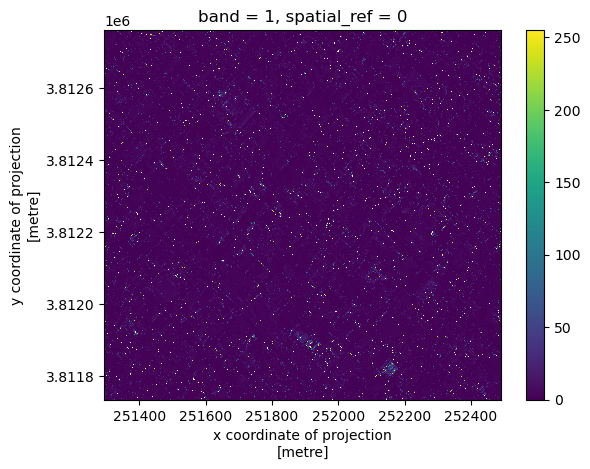

In [41]:
ndvi.plot()